# RTT-grounded graphs

Builds the topology graphs **from the RTT measurements themselves**, so the graph-ID / ITDK-ID
mapping problem never arises.

1. Each traceroute in `caida_real_rtt_supervised.csv` gives an ordered hop list (`path_ips`).
2. Hop IPs are resolved to ITDK node IDs by streaming `midar-iff-snmp.nodes` (alias resolution).
   An IP that ITDK does not know becomes its own node `IP:<addr>`.
3. **Every traceroute that reached its destination is used.** A hop that never answered becomes an
   anonymous router `ANON:<n>`, and an unresolved private address (not globally unique) becomes
   `PRIV:<n>`. Both are shared only between traceroutes with an identical route prefix, so adjacent
   hops are still real links and the RTT belongs to the whole path. `anon_hops` counts these
   inferred nodes on each path so they can be filtered.
4. Measured pairs are split into `NUM_GRAPHS` graphs (seeded). Each graph is the union of its
   measured paths.

Output: `graph_XX.csv` edge lists, `path_level_rtt_dataset.csv` (one row per graph / source /
destination / path, `path_method = traceroute_measured`) and `unmapped_rtt_rows.csv` with a reason
for every traceroute that was not used.


In [9]:
from collections import Counter
from pathlib import Path
import ipaddress
import re

import networkx as nx
import numpy as np
import pandas as pd

try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    pass

PROJECT_ROOT = Path("/content/drive/My Drive/Thesis/DeepNT_Output")
RTT_FILE = PROJECT_ROOT / "real_rtt" / "caida_real_rtt_supervised.csv"
NODES_FILE = Path("/content/drive/My Drive/DataSet/midar-iff-snmp.nodes")
OUT_DIR = PROJECT_ROOT / "graphs_rtt"      # new folder: the old graph_XX.csv are left untouched

NUM_GRAPHS = 15
SEED = 2026
RTT_AGG = "median"                          # robust to RTT outliers; "mean" for a plain average
PATH_METHOD = "traceroute_measured"


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 1. Load RTT and rebuild each traceroute's IP sequence

In [10]:
REQUIRED = ['measurement_id', 'source_ip', 'destination_ip', 'hop_numbers', 'path_ips',
            'destination_responded', 'destination_hop_number', 'destination_rtt_ms']
raw = pd.read_csv(RTT_FILE, usecols=REQUIRED)
print(f"Loaded {len(raw):,} traceroutes")

# Unit gate: the column is named *_ms but warts stores microseconds, so verify from the values.
raw['rtt_raw'] = pd.to_numeric(raw['destination_rtt_ms'], errors='coerce')
median_raw = raw['rtt_raw'].median()
unit_div = 1000.0 if median_raw > 1000 else 1.0
raw['rtt_ms'] = raw['rtt_raw'] / unit_div
print(f"Median raw RTT {median_raw:,.1f} -> treated as {'microseconds' if unit_div == 1000 else 'milliseconds'}; "
      f"median RTT = {raw['rtt_ms'].median():.1f} ms (sanity-check this)")

raw['responded'] = raw['destination_responded'].astype(str).str.lower().isin(['true', '1', '1.0', 'yes'])
raw['destination_hop_number'] = pd.to_numeric(raw['destination_hop_number'], errors='coerce')

IPV4 = re.compile(r'\d{1,3}(?:\.\d{1,3}){3}')
INT = re.compile(r'\d+')


def ip_sequence(row):
    """([source, hop1, ..., destination], None); a hop that never answered is None. Else (None, reason)."""
    if not row.responded or pd.isna(row.rtt_ms):
        return None, 'no_rtt'
    ips = IPV4.findall(str(row.path_ips))
    hops = [int(h) for h in INT.findall(str(row.hop_numbers))]
    if not ips or len(ips) != len(hops):
        return None, 'hop_parse_mismatch'
    if hops[0] < 1 or any(b <= a for a, b in zip(hops, hops[1:])):
        return None, 'hop_order_invalid'
    if ips[-1] == row.destination_ip:
        end_hop = hops[-1]
    elif row.destination_hop_number > hops[-1]:
        ips.append(row.destination_ip)
        hops.append(int(row.destination_hop_number))
        end_hop = hops[-1]
    else:
        return None, 'destination_not_at_end'
    by_hop = dict(zip(hops, ips))
    return [row.source_ip] + [by_hop.get(h) for h in range(1, end_hop + 1)], None


ip_seqs, reasons = {}, {}
for row in raw.itertuples():
    seq, why = ip_sequence(row)
    if why:
        reasons[row.Index] = why
    else:
        ip_seqs[row.Index] = seq

n_silent = sum(ip is None for seq in ip_seqs.values() for ip in seq)
print(f"Usable traceroutes: {len(ip_seqs):,} / {len(raw):,}  ({n_silent:,} silent hops become ANON nodes)")
if reasons:
    print(pd.Series(Counter(reasons.values())).sort_values(ascending=False).to_string())


Loaded 51,072 traceroutes
Median raw RTT 218,208.5 -> treated as microseconds; median RTT = 218.2 ms (sanity-check this)
Usable traceroutes: 51,072 / 51,072  (104,774 silent hops become ANON nodes)


## 2. Resolve hop IPs to ITDK nodes

Streams the `.nodes` file once and keeps only the IPs we need, so memory is bounded by the number of
distinct hop IPs, not by the size of ITDK.

In [11]:
wanted_ips = {ip for seq in ip_seqs.values() for ip in seq if ip}
print(f"Resolving {len(wanted_ips):,} distinct IPs against {NODES_FILE.name} ...")

ip_to_node = {}
with open(NODES_FILE, 'r', encoding='utf-8', errors='replace') as f:
    for n_lines, line in enumerate(f, 1):
        if line[:4] == 'node':
            parts = line.split()
            for tok in parts[2:]:
                if tok in wanted_ips:
                    ip_to_node[tok] = parts[1].rstrip(':')
        if n_lines % 25_000_000 == 0:
            print(f"  ...{n_lines:,} lines, {len(ip_to_node):,} IPs resolved")

print(f"Resolved {len(ip_to_node):,} / {len(wanted_ips):,} IPs to ITDK nodes "
      f"({100 * len(ip_to_node) / max(len(wanted_ips), 1):.1f}%); the rest stay as IP:<addr> nodes")


Resolving 117,714 distinct IPs against midar-iff-snmp.nodes ...
  ...25,000,000 lines, 53,731 IPs resolved
  ...50,000,000 lines, 55,814 IPs resolved
  ...75,000,000 lines, 60,997 IPs resolved
  ...100,000,000 lines, 62,045 IPs resolved
  ...125,000,000 lines, 65,194 IPs resolved
  ...150,000,000 lines, 68,369 IPs resolved
Resolved 70,651 / 117,714 IPs to ITDK nodes (60.0%); the rest stay as IP:<addr> nodes


## 3. Node paths, graph assignment, path-level dataset

In [16]:
anon_ids = {}


def scoped_node(prefix, kind, token):
    """Anonymous / private nodes are identified by (route prefix, kind, token): two traceroutes share
    one only if everything before it is identical."""
    key = (tuple(prefix), kind, token)
    if key not in anon_ids:
        anon_ids[key] = f"{kind}:{len(anon_ids)}"
    return anon_ids[key]


def to_node_path(ip_seq):
    nodes = []
    for hop, ip in enumerate(ip_seq):
        if ip is None:
            n = scoped_node(nodes, 'ANON', hop)
        else:
            n = ip_to_node.get(ip)
            if n is None:
                try:
                    is_global = ipaddress.ip_address(ip).is_global
                except ValueError:
                    return None, 'invalid_ip'
                n = f"IP:{ip}" if is_global else scoped_node(nodes, 'PRIV', ip)
        if not nodes or nodes[-1] != n:          # interfaces of one router appear as one node
            nodes.append(n)
    if len(nodes) < 2:
        return None, 'src_equals_dst'
    if len(set(nodes)) != len(nodes):
        return None, 'loop_in_path'
    return nodes, None


node_paths = {}
for idx, seq in ip_seqs.items():
    nodes, why = to_node_path(seq)
    if why:
        reasons[idx] = why
    else:
        node_paths[idx] = nodes

# every measurement of a (source, destination) pair goes to the same graph; seeded, reproducible
pairs = sorted({(p[0], p[-1]) for p in node_paths.values()})
order = np.random.default_rng(SEED).permutation(len(pairs))
graph_of = {pair: f"graph_{int(order[i]) % NUM_GRAPHS + 1:02d}" for i, pair in enumerate(pairs)}

used = pd.DataFrame({
    'graph_id': [graph_of[(p[0], p[-1])] for p in node_paths.values()],
    'source': [p[0] for p in node_paths.values()],
    'destination': [p[-1] for p in node_paths.values()],
    'path': ['|'.join(p) for p in node_paths.values()],
    'rtt_ms': raw.loc[list(node_paths), 'rtt_ms'].to_numpy(),
})

merged_df = (used.groupby(['graph_id', 'source', 'destination', 'path'], as_index=False)
                 .agg(rtt_ms=('rtt_ms', RTT_AGG), measurement_count=('rtt_ms', 'size')))
merged_df['path_edges'] = merged_df['path'].map(
    lambda s: '|'.join(f"{a}-{b}" for a, b in zip(s.split('|'), s.split('|')[1:])))
merged_df['path_length'] = merged_df['path'].str.count(r'\|')
merged_df['anon_hops'] = merged_df['path'].map(
    lambda s: sum(n.startswith(('ANON:', 'PRIV:')) for n in s.split('|')))
merged_df['path_method'] = PATH_METHOD
merged_df = merged_df[['graph_id', 'source', 'destination', 'rtt_ms', 'measurement_count',
                       'path', 'path_edges', 'path_length', 'path_method', 'anon_hops']]

unmapped_df = raw.loc[list(reasons), ['measurement_id', 'source_ip', 'destination_ip']].assign(
    reason=pd.Series(reasons))

print(f"Path-level rows: {len(merged_df):,}  (from {len(node_paths):,} traceroutes, {len(pairs):,} pairs)")
print(f"Coverage: {len(node_paths):,} / {len(raw):,} traceroutes attached ({100 * len(node_paths) / len(raw):.1f}%)")
print(f"Paths containing an inferred (ANON/PRIV) node: {(merged_df['anon_hops'] > 0).mean():.1%}")
print(f"Unused traceroutes: {len(unmapped_df):,}")
if len(unmapped_df):
    print(unmapped_df['reason'].value_counts().to_string())


Path-level rows: 51,025  (from 51,025 traceroutes, 51,024 pairs)
Coverage: 51,025 / 51,072 traceroutes attached (99.9%)
Paths containing an inferred (ANON/PRIV) node: 79.0%
Unused traceroutes: 47
reason
loop_in_path    47


## 4. Build, verify and save the graphs

In [17]:
edge_counts = {}
for row in merged_df.itertuples():
    nodes = row.path.split('|')
    ec = edge_counts.setdefault(row.graph_id, Counter())
    for a, b in zip(nodes, nodes[1:]):
        ec[tuple(sorted((a, b)))] += row.measurement_count

graphs = {}
for gid, ec in sorted(edge_counts.items()):
    G = nx.Graph()
    G.add_weighted_edges_from((a, b, c) for (a, b), c in ec.items())
    graphs[gid] = G

# every path edge must be an edge of its own graph
for row in merged_df.itertuples():
    G = graphs[row.graph_id]
    assert all(G.has_edge(*e.split('-', 1)) for e in row.path_edges.split('|')), row

OUT_DIR.mkdir(parents=True, exist_ok=True)
for gid, ec in edge_counts.items():
    pd.DataFrame([(a, b, c) for (a, b), c in ec.items()],
                 columns=['source', 'target', 'measurements']).to_csv(OUT_DIR / f"{gid}.csv", index=False)
merged_df.to_csv(OUT_DIR / "path_level_rtt_dataset.csv", index=False)
unmapped_df.to_csv(OUT_DIR / "unmapped_rtt_rows.csv", index=False)

itdk_share = np.mean([n.startswith('N') for G in graphs.values() for n in G])
print(f"Saved to {OUT_DIR}")
for gid, G in graphs.items():
    n_paths = (merged_df['graph_id'] == gid).sum()
    print(f"  {gid}: {G.number_of_nodes():>6,} nodes {G.number_of_edges():>6,} edges {n_paths:>6,} paths")
print(f"ITDK-resolved share of graph nodes: {100 * itdk_share:.1f}%")
merged_df.head(10)


Saved to /content/drive/My Drive/Thesis/DeepNT_Output/graphs_rtt
  graph_01: 16,557 nodes 18,407 edges  3,402 paths
  graph_02: 16,625 nodes 18,496 edges  3,402 paths
  graph_03: 16,650 nodes 18,523 edges  3,403 paths
  graph_04: 16,723 nodes 18,614 edges  3,402 paths
  graph_05: 16,661 nodes 18,495 edges  3,402 paths
  graph_06: 16,769 nodes 18,739 edges  3,402 paths
  graph_07: 16,716 nodes 18,565 edges  3,402 paths
  graph_08: 16,702 nodes 18,594 edges  3,402 paths
  graph_09: 16,652 nodes 18,546 edges  3,402 paths
  graph_10: 16,715 nodes 18,611 edges  3,401 paths
  graph_11: 16,899 nodes 18,742 edges  3,401 paths
  graph_12: 16,727 nodes 18,582 edges  3,401 paths
  graph_13: 16,846 nodes 18,789 edges  3,401 paths
  graph_14: 16,637 nodes 18,485 edges  3,401 paths
  graph_15: 16,560 nodes 18,380 edges  3,401 paths
ITDK-resolved share of graph nodes: 55.8%


,graph_id,source,destination,rtt_ms,measurement_count,path,path_edges,path_length,path_method,anon_hops
0,graph_01,N10251189,IP:1.15.179.67,336.888,1,N10251189|N10251192|N10245194|N8970414|N28051|...,N10251189-N10251192|N10251192-N10245194|N10245...,14,traceroute_measured,1
1,graph_01,N10251189,IP:1.190.210.86,383.091,1,N10251189|N10251192|N10245194|N8970414|N28051|...,N10251189-N10251192|N10251192-N10245194|N10245...,20,traceroute_measured,2
2,graph_01,N10251189,IP:1.226.86.89,340.032,1,N10251189|N10251192|N10245194|N8970414|N28051|...,N10251189-N10251192|N10251192-N10245194|N10245...,19,traceroute_measured,7
3,graph_01,N10251189,IP:1.234.92.117,369.279,1,N10251189|N10251192|N10245194|N8970414|N28051|...,N10251189-N10251192|N10251192-N10245194|N10245...,19,traceroute_measured,7
4,graph_01,N10251189,IP:1.254.189.79,371.222,1,N10251189|N10251192|N10245194|N8970414|N28051|...,N10251189-N10251192|N10251192-N10245194|N10245...,19,traceroute_measured,7
5,graph_01,N10251189,IP:100.37.232.34,185.268,1,N10251189|N10251192|N10245194|N8970414|N28051|...,N10251189-N10251192|N10251192-N10245194|N10245...,13,traceroute_measured,1
6,graph_01,N10251189,IP:100.38.94.113,184.463,1,N10251189|N10251192|N10245194|N8970414|N28051|...,N10251189-N10251192|N10251192-N10245194|N10245...,11,traceroute_measured,0
7,graph_01,N10251189,IP:101.108.179.243,310.960,1,N10251189|N10251192|N10245194|N8970414|N28051|...,N10251189-N10251192|N10251192-N10245194|N10245...,11,traceroute_measured,1
8,graph_01,N10251189,IP:101.108.200.2,305.667,1,N10251189|N10251192|N10245194|N8970414|N28051|...,N10251189-N10251192|N10251192-N10245194|N10245...,12,traceroute_measured,1
9,graph_01,N10251189,IP:101.17.25.201,366.428,1,N10251189|N10251192|N10245194|N8970414|N28051|...,N10251189-N10251192|N10251192-N10245194|N10245...,19,traceroute_measured,1


## 5. Audit: is the RTT attached correctly?

Recomputes every path-level RTT straight from the raw CSV and compares, then prints three raw traceroutes next to their dataset rows.

In [18]:
# Independent audit: recompute every path-level RTT straight from the raw file and compare.
checks = {}

expected = (pd.DataFrame({
                'graph_id': used['graph_id'].to_numpy(),
                'source': used['source'].to_numpy(),
                'destination': used['destination'].to_numpy(),
                'path': used['path'].to_numpy(),
                'rtt_ms': (raw.loc[list(node_paths), 'destination_rtt_ms'] / unit_div).to_numpy(),
            })
            .groupby(['graph_id', 'source', 'destination', 'path'], as_index=False)
            .agg(rtt_ms=('rtt_ms', RTT_AGG), measurement_count=('rtt_ms', 'size')))
cmp = merged_df.merge(expected, on=['graph_id', 'source', 'destination', 'path'], suffixes=('', '_raw'))
checks['every row matches an independent recomputation from the raw RTT file'] = (
    len(cmp) == len(merged_df) == len(expected)
    and np.allclose(cmp['rtt_ms'], cmp['rtt_ms_raw']) and (cmp['measurement_count'] == cmp['measurement_count_raw']).all())

plist = merged_df['path'].str.split('|')
checks['path starts at source and ends at destination'] = bool(
    (plist.str[0] == merged_df['source']).all() and (plist.str[-1] == merged_df['destination']).all())
checks['path_length = hops = edges in path_edges'] = bool(
    (merged_df['path_length'] == plist.str.len() - 1).all()
    and (merged_df['path_edges'].str.count(r'\|') + 1 == merged_df['path_length']).all())
checks['every path edge exists in its graph'] = all(
    graphs[r.graph_id].has_edge(*e.split('-', 1)) for r in merged_df.itertuples() for e in r.path_edges.split('|'))
checks['no node repeats inside a path (simple paths)'] = bool((plist.map(len) == plist.map(lambda p: len(set(p)))).all())
checks['RTT lives only on the path row (no per-edge RTT column)'] = not any(
    'rtt' in c for c in pd.read_csv(OUT_DIR / 'graph_01.csv', nrows=1).columns)
checks['all RTT > 0 and finite'] = bool(np.isfinite(merged_df['rtt_ms']).all() and (merged_df['rtt_ms'] > 0).all())

for name, ok in checks.items():
    print(f"[{'PASS' if ok else 'FAIL'}] {name}")

print(f"\nCorr(RTT, hop count) = {merged_df['rtt_ms'].corr(merged_df['path_length']):.2f}  (should be positive)")
print(merged_df['rtt_ms'].describe().round(1).to_string())

print("\nSpot check: raw traceroute -> node path -> RTT for 3 random rows")
for idx in np.random.default_rng(1).choice(list(node_paths), size=min(3, len(node_paths)), replace=False):
    r = raw.loc[idx]
    print(f"\nmeasurement {r.measurement_id}: {r.source_ip} -> {r.destination_ip}")
    print(f"  raw hops     : {' '.join(ip or '*' for ip in ip_seqs[idx])}")
    print(f"  node path    : {' '.join(node_paths[idx])}")
    print(f"  raw RTT      : {r.destination_rtt_ms} -> {r.rtt_ms:.3f} ms")
    row = merged_df[(merged_df['graph_id'] == graph_of[(node_paths[idx][0], node_paths[idx][-1])])
                    & (merged_df['path'] == '|'.join(node_paths[idx]))].iloc[0]
    print(f"  dataset row  : {row.graph_id}, rtt_ms={row.rtt_ms:.3f}, hops={row.path_length}, n={row.measurement_count}")


[PASS] every row matches an independent recomputation from the raw RTT file
[PASS] path starts at source and ends at destination
[PASS] path_length = hops = edges in path_edges
[PASS] every path edge exists in its graph
[PASS] no node repeats inside a path (simple paths)
[PASS] RTT lives only on the path row (no per-edge RTT column)
[PASS] all RTT > 0 and finite

Corr(RTT, hop count) = 0.08  (should be positive)
count    51025.0
mean       221.7
std        214.2
min          0.4
25%        141.9
50%        218.1
75%        283.1
max      23789.3

Spot check: raw traceroute -> node path -> RTT for 3 random rows

measurement .acc-gh.team-probing.c012588.20250310.warts:219021: 196.49.14.12 -> 73.115.179.89
  raw hops     : 196.49.14.12 196.49.14.1 197.221.70.89 196.14.240.4 168.209.160.109 168.209.160.108 168.209.246.1 149.6.148.129 154.54.62.5 154.54.60.14 154.54.47.145 154.54.11.166 96.110.46.133 96.110.40.122 96.216.148.58 162.151.134.130 69.139.210.190 73.115.179.89
  node path    : N

## 6. Look at the graphs

Full graph with three measured paths highlighted (fastest, median, slowest), each drawn as a chain with its single RTT, plus RTT vs hop count.

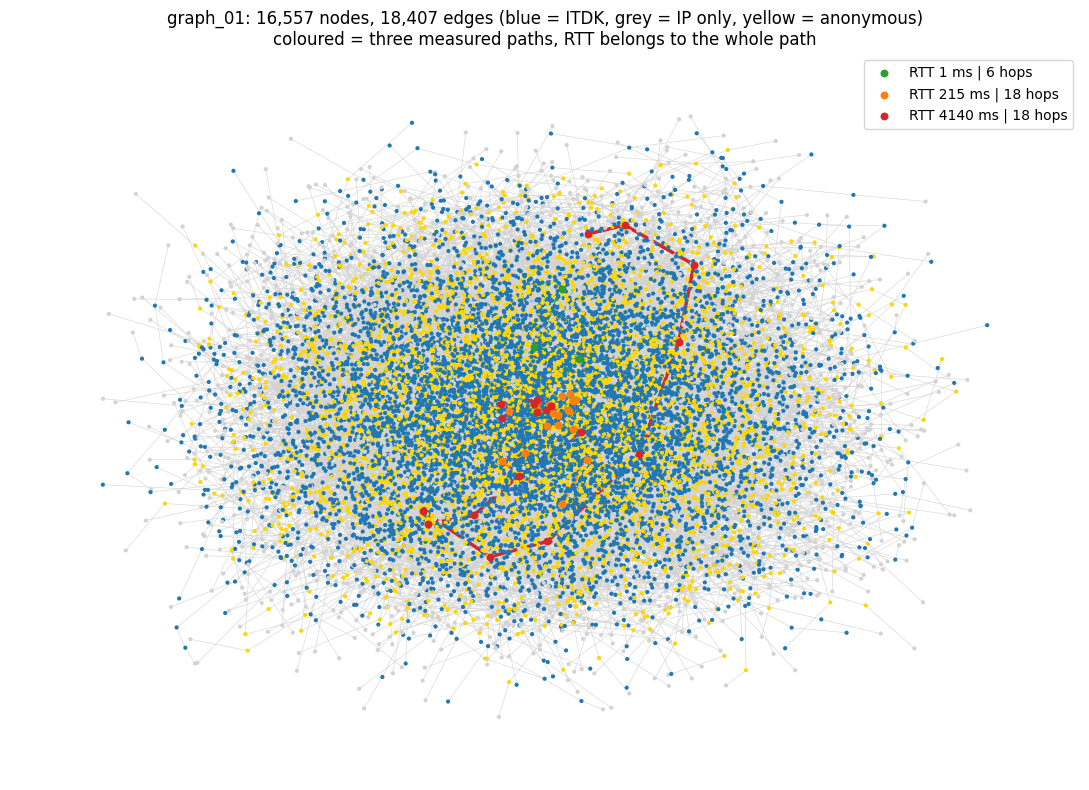

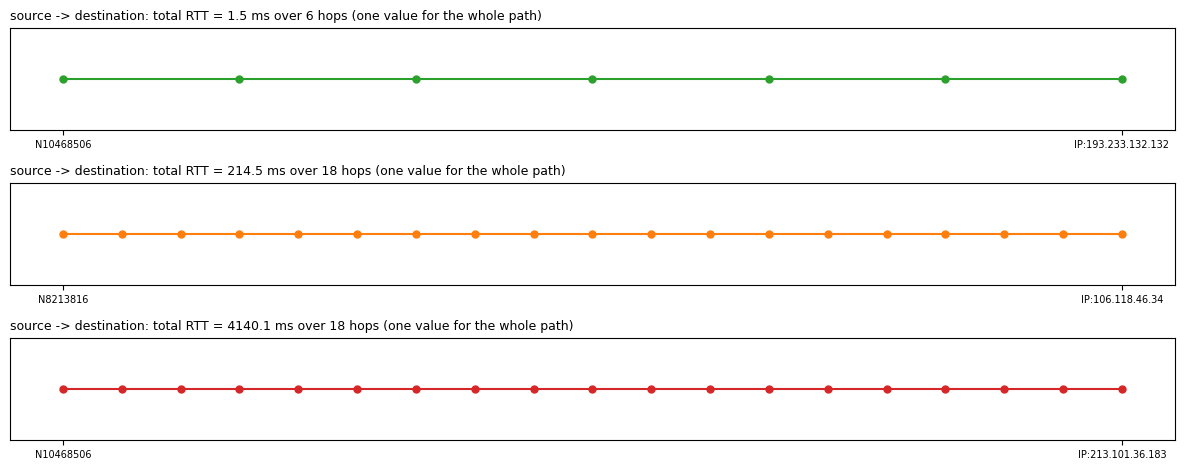

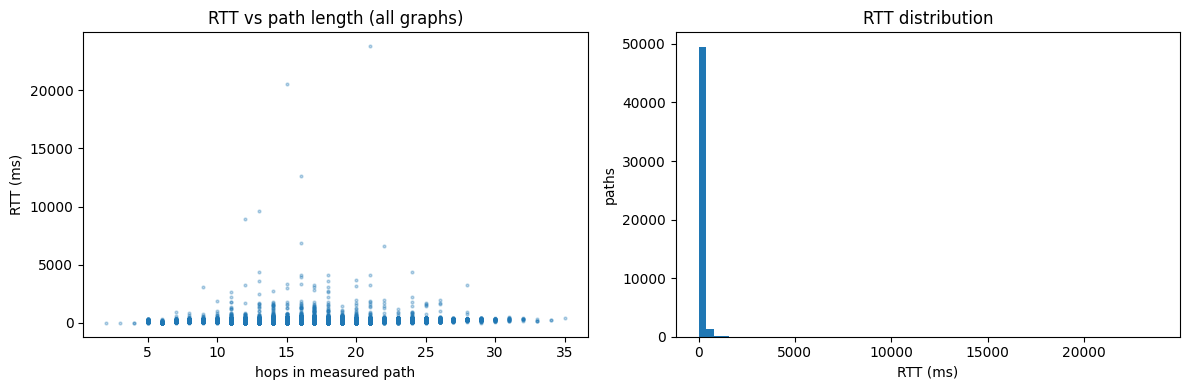

In [19]:
import matplotlib.pyplot as plt

gid = 'graph_01' if 'graph_01' in graphs else next(iter(graphs))
G = graphs[gid]
rows = merged_df[merged_df['graph_id'] == gid].sort_values('rtt_ms').reset_index(drop=True)
picks = rows.iloc[sorted({0, len(rows) // 2, len(rows) - 1})]      # fastest, median, slowest path
colors = ['tab:green', 'tab:orange', 'tab:red']

pos = nx.spring_layout(G, seed=SEED, iterations=60)
kind_color = lambda n: 'tab:blue' if n.startswith('N') else ('gold' if n[:3] in ('ANO', 'PRI') else 'lightgray')

fig, ax = plt.subplots(figsize=(11, 8))
nx.draw_networkx_edges(G, pos, ax=ax, edge_color='lightgray', width=0.4)
nx.draw_networkx_nodes(G, pos, ax=ax, node_size=4,
                       node_color=[kind_color(n) for n in G])
for (_, r), c in zip(picks.iterrows(), colors):
    nodes = r['path'].split('|')
    edges = list(zip(nodes, nodes[1:]))
    nx.draw_networkx_edges(G, pos, ax=ax, edgelist=edges, edge_color=c, width=2.5)
    nx.draw_networkx_nodes(G, pos, ax=ax, nodelist=nodes, node_size=22, node_color=c,
                           label=f"RTT {r['rtt_ms']:.0f} ms | {r['path_length']} hops")
ax.set_title(f"{gid}: {G.number_of_nodes():,} nodes, {G.number_of_edges():,} edges "
             f"(blue = ITDK, grey = IP only, yellow = anonymous)\ncoloured = three measured paths, RTT belongs to the whole path")
ax.legend(loc='upper right'); ax.axis('off'); plt.tight_layout(); plt.show()

fig, axes = plt.subplots(len(picks), 1, figsize=(12, 1.6 * len(picks)))
for ax, (_, r), c in zip(np.atleast_1d(axes), picks.iterrows(), colors):
    nodes = r['path'].split('|')
    xs = range(len(nodes))
    ax.plot(xs, [0] * len(nodes), '-o', color=c, ms=5)
    ax.set_yticks([]); ax.set_xticks([0, len(nodes) - 1])
    ax.set_xticklabels([nodes[0], nodes[-1]], fontsize=7)
    ax.set_title(f"source -> destination: total RTT = {r['rtt_ms']:.1f} ms over {r['path_length']} hops "
                 f"(one value for the whole path)", fontsize=9, loc='left')
plt.tight_layout(); plt.show()

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4))
a1.scatter(merged_df['path_length'], merged_df['rtt_ms'], s=4, alpha=0.3)
a1.set(xlabel='hops in measured path', ylabel='RTT (ms)', title='RTT vs path length (all graphs)')
a2.hist(merged_df['rtt_ms'], bins=60)
a2.set(xlabel='RTT (ms)', ylabel='paths', title='RTT distribution')
plt.tight_layout(); plt.show()
